# Hypothetical extreme planet: the $A_B$ bias at the limits of $a/R_\star$

Where does the $a/R_\star$ axis of the bias maps physically end, and how large does the bias from neglecting hyperillumination get there? The host is not fixed to a spectral type: the Roche limit depends only on the density ratio $\rho_\star/\rho_p$, so the analysis runs over that ratio, and spectral types enter only through the main-sequence relation `rho_star(T_eff)` (`astro_utils`).

As in `Bias_Maps.ipynb`, the noiseless data are a `hyperillum` phase curve at $A_{B,\rm true}$ with no heat redistribution, fitted with the point-source models with a free baseline: $A_B$ only (`naive`) and $A_B$ + $F$ jointly (`naive_redist`; the truth has $F = 0$, so the fitted $F$ is the bias).

1. **The limits** -- the $a/R_\star$ limits and where the record holders (`anchors`) sit relative to their Roche limit.
2. **Figure A, the limit curve** -- bias and measurability as functions of $a/R_\star$ from just outside the contact limit outwards.
3. **Figure B, the Roche frontier** -- the $(a/R_\star, T_{\rm eff})$ map with the Roche limit through it, and the largest physically reachable bias.
4. **Figure C, Roche-limit planets** -- one planet per density ratio exactly at its Roche limit: fits, temperature maps, retrieval next to the anchors.

In [1]:
import numpy as np
import pandas as pd
import os
import contextlib, io
import matplotlib.pyplot as plt
from dataclasses import replace
from astropy import constants as const
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman as sp
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from astro_utils import *
import batman_utils
from simple_bias_analysis import *
from HItargets_utils import *
from paper_plot_utils import paper_figure, paper_theme

# Exoplanet Archive (planet overlay on the map, anchor densities, the observed edge)
AGG = os.path.join(os.path.dirname(os.path.abspath('')), 'NASAExoplanetArchive', 'NASAExoArchive_2026-08-21_aggregate_short.csv')

In [2]:
# Reference geometry: every sweep point and map cell inherits it for whatever is not swept (the same values as Bias_Maps.ipynb).
incl_ref  = 90.     # [deg] central transit, so every point occults
rp_rs_ref = 0.015   # Rp/Rs held fixed
T_eff_ref = 4000.   # [K] T_eff held fixed on the limit curve (Figure A); Figure B sweeps it
ref = reference_planet(rp_rs=rp_rs_ref, T_eff=T_eff_ref, incl=incl_ref)   # a/Rs is swept; the period is replaced per sweep point in Figure A (Kepler III)

# The real record holders: marks on the limit curve, fitted next to the hypothetical planets in Figure C. The first one supplies the noise level of the sweep.
anchors = hi_planets_by_name(["TOI-2431 b", "K2-141 b"])

u = [0.15, 0.08]                            # Band-integrated (MIR) quadratic stellar limb darkening coefficients [u1, u2] (placeholders from grey Eddington atmosphere, will be set by theoretical stellar atmosphere models)
u_B = 0.6                                   # Bolometric linear stellar limb darkening coefficient (placeholder, from Sadh_Gavassino_2026)

In [3]:
# Albedo assumptions

# Geometric albedo in the optical from Zieba 2022 (using Kepler, Spitzer data are not able to constrain the albedo at 4.5 µm). This is likely an overestimate. Zieba 2022 assumed A_B=A for Kepler.
Ag = 0.28

# Assuming grey Lambertian reflectance. PROBABLY UNPHYSICAL!
# A_B basically unrelated to A (MIR band integrated), mainly influenced by albedo in optical (lambda_max=630nm) + clouds/atmosphere
A_B_true = 3/2 * Ag # 0.42; the SAME assumed albedo for every sweep point, map cell and planet

# ASSUMPTION (!)
# Model for band-integrated albedo in the observing band (MIR)
A_model = ConstantBandAlbedo(.1) # Band-integrated albedo of rocky surface fixed to A=0.1 (small reflected part) in MIR
# A_model = ScaledBandAlbedo(1.) # Band-integrated albedo in MIR of rocky surface set to A=A_B (probably overestimate).

In [4]:
# Filter and observation
instrument = "MIRI/LRS" # "JWST_NIRSpec.G395H_NRS1", "MIRI/LRS", "MIRI/F1280W"
filter_path = filter_loc(instrument)
l1, l2 = filter_lambda(instrument)
n_bins = 27     # number of bins in one orbit
n_orbits = 5    # number of orbits observed; enters only the Fisher sigmas and chi^2 (the biases are noise-independent)


# sigma_1min is a placeholder for the map of Figure B (the bias does not depend on the noise scale). The limit curve and the per-planet fits replace it: sigma_sweep below, PandExo for the anchors.
cfg = FittingConfig(planet=ref, filter_path=filter_path,
                    l1=l1, l2=l2, A_=A_model,
                    sigma_1min=100., n_orbits=n_orbits, n_bins=n_bins,
                    reflected=True, u_B=u_B, u=u)
kw = dict(n_lo=300, n_la=150)     # n_layers is left to the per-model default of pcurve_params

# Noise of the limit curve and of the hypothetical planets: no PandExo without a real host, so the first anchor's per-minute noise is used for them ("as if the host were as bright as TOI-2431 b's").
sigma_anchors = rms_1min_pandexo_sample(list(anchors), instrument)   # PandExo is not cached: keep this dict
sigma_sweep = sigma_anchors[next(iter(anchors))]
print("sigma_1min [" + instrument + "]: " + ", ".join(f"{nm} {s:.1f} ppm/min" for nm, s in sigma_anchors.items()) + f"; the limit curve and the hypothetical planets use {sigma_sweep:.1f} ppm/min")

set_plot_style()
geom = rf"$A_B$ = {A_B_true:.2f}, $i$ = {incl_ref:g}°"   # for the figure titles

Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
Running Single Case w/ User Instrument Dict
Optimization Reqested: Computing Duty Cycle
Finished Duty Cycle Calc
Starting Out of Transit Simulation
End out of Transit
Starting In Transit Simulation
End In Transit
sigma_1min [MIRI/LRS]: TOI-2431 b 91.9 ppm/min, K2-141 b 154.5 ppm/min; the limit curve and the hypothetical planets use 91.9 ppm/min


## 1. The limits

- **Asymptote $a/R_\star \to 1$.** The stellar angular radius $\arcsin(R_\star/a)$ goes to $90°$ and the unlit fraction $\sigma_{\rm night} = \tfrac12\,[1 - (R_\star - R_p)/a]$ to $R_p/(2a)$: no nightside is left, every curve of this notebook saturates there. (Area fractions as in Knuth et al. 2017 / Carter et al. 2024, `PlanetParams.fraction_illuminated`.)
- **Contact, $a/R_\star = 1 + R_p/R_\star$.** The inner edge of anything computable (SPIDERMAN stops below it). Hatched in the figures.
- **Roche limit, $a_{\rm R}/R_\star = c\,(\rho_\star/\rho_p)^{1/3}$ with $c = 2.456$** (Rappaport, Sanchis-Ojeda, Rogers, Petigura & Winn 2013, eq. 1; `roche_limit_a_rs`). The physical wall. The incompressible-fluid value is the right one for any planet-sized body, molten or not -- self-gravity dwarfs material strength at that scale -- and a centrally condensed planet survives somewhat inside it, so this is the conservative edge. In period the limit is host-independent, $P_{\rm R} = \sqrt{3\pi c^3/(G\rho_p)}$ (their eq. 2, `roche_limit_period_h`); in $a/R_\star$ it moves with the host through $\rho_\star$ (`kepler_period_days`), so on an $a/R_\star$ axis it is a family labelled by $\rho_\star/\rho_p$. Small ratios (dense planet, low-density host) put the wall at the contact limit; ratios around 1 and above (M dwarfs) push it out to several stellar radii.
- **Soft limits.** Tidal decay (tens of Myr at the Roche distance) and the observed population edge, where the `anchors` sit.
- **Internal limit.** Where a fit rails against $A_B \in [0, 1]$ (the point-source model cannot reproduce the truth at any albedo, `fit_railed`) the $A_B$ bias is undefined; the misfit $\chi^2$ stays defined.

`rho_star(T_eff)` is the main-sequence mean density from the Pecaut & Mamajek (2013) table in `astro_utils`; the anchors' densities come from the archive (`archive_densities`).

In [5]:
RHO_P_REF = 8.0                          # [g/cm^3] mean density of the Roche-limit planets: Earth composition compressed to ~1.5 Earth radii, matching the archive densities of the anchors
RHO_P_CASES = {"Earth bulk density": 5.5, "Earth composition at 1.5 R⊕": RHO_P_REF}   # [g/cm^3] compositions of the Roche curves on the map (Figure B)
RHO_RATIOS = (0.1, 0.3, 1., 3.)          # rho_star / rho_p of the Roche limits marked on the limit curve and of the Roche-limit planets (Figure C)

print(f"Roche limit per density ratio, and the main-sequence host with that rho_star for rho_p = {RHO_P_REF:g} g/cm^3 (period at the limit: {roche_limit_period_h(RHO_P_REF):.2f} h, host-independent):")
for r in RHO_RATIOS:
    print(f"  rho_star/rho_p = {r:<4g}:  a_R/Rs = {roche_limit_a_rs(r):.2f};  host rho_star = {r * RHO_P_REF:.1f} g/cm^3 -> T_eff = {main_sequence_T_eff(r * RHO_P_REF):.0f} K")
print(f"contact limit at the reference Rp/Rs: a/Rs = {1 + rp_rs_ref:.3f}")

print("\nanchors relative to their own Roche limit (archive densities):")
for nm, pl in anchors.items():
    rho_s, rho_p = archive_densities(nm)
    a_R = roche_limit_a_rs(rho_s / rho_p)
    print(f"  {nm}: a/Rs = {pl.R / pl.r2:.2f}, rho_star = {rho_s:.2f}, rho_p = {rho_p:.2f} g/cm^3, ratio = {rho_s / rho_p:.2f} -> a_R/Rs = {a_R:.2f}, a/a_R = {pl.R / pl.r2 / a_R:.2f}")

edge = rocky_sample(AGG, "st_teff", (2000., 10000.), a_rs_lim=(1., 10.)).nsmallest(5, "a_over_r2")   # the observed edge, same sample definition as the map overlays
print("\nobserved edge (rocky, Rp < 1.7 R_Earth): " + ", ".join(f"{r.pl_name} {r.a_over_r2:.2f}" for _, r in edge.iterrows()))

Roche limit per density ratio, and the main-sequence host with that rho_star for rho_p = 8 g/cm^3 (period at the limit: 4.49 h, host-independent):
  rho_star/rho_p = 0.1 :  a_R/Rs = 1.14;  host rho_star = 0.8 g/cm^3 -> T_eff = 6236 K
  rho_star/rho_p = 0.3 :  a_R/Rs = 1.64;  host rho_star = 2.4 g/cm^3 -> T_eff = 5225 K
  rho_star/rho_p = 1   :  a_R/Rs = 2.46;  host rho_star = 8.0 g/cm^3 -> T_eff = 3518 K
  rho_star/rho_p = 3   :  a_R/Rs = 3.54;  host rho_star = 24.0 g/cm^3 -> T_eff = 3105 K
contact limit at the reference Rp/Rs: a/Rs = 1.015

anchors relative to their own Roche limit (archive densities):
  TOI-2431 b: a/Rs = 2.08, rho_star = 3.78, rho_p = 9.44 g/cm^3, ratio = 0.40 -> a_R/Rs = 1.81, a/a_R = 1.15
  K2-141 b: a/Rs = 2.29, rho_star = 3.15, rho_p = 7.93 g/cm^3, ratio = 0.40 -> a_R/Rs = 1.80, a/a_R = 1.27

observed edge (rocky, Rp < 1.7 R_Earth): TOI-2431 b 2.08, TOI-2260 b 2.22, Kepler-1340 b 2.31, K2-141 b 2.36, KOI-1843.03 2.39


## 2. Figure A: the limit curve

`bias_vs_a_rs` refits both models at every $a/R_\star$ of `a_rs_sweep` at the reference geometry. The bias depends neither on the noise nor on the period; the Fisher $\sigma$ and $\chi^2$ do, so each point gets the Kepler-III period of a circular orbit around a main-sequence star of `T_eff_ref` and the noise `sigma_sweep`.

Three panels on a shared log axis (`plot_limit_curve`): the **geometry** (area fractions, stellar angular radius on the right; the fully illuminated and nightside fractions differ only by $R_p/a$), the **bias** ($\Delta A_B$ of both fits, the spurious $F$ on the right axis, hollow markers where a fit railed), and the **measurability** -- $|\Delta A_B|/\sigma_{A_B}$ of both fits, $\sqrt{\Delta\chi^2_F}$ (the significance with which the joint fit would report $F > 0$ on data without redistribution, `Bias_Maps.ipynb` §2.5) and $\sqrt{\chi^2}$ of the best $A_B$-only fit (the significance with which that model could be rejected from the residuals). All scale as $1/\sigma_{1\rm min}$: another noise level shifts every curve vertically. Vertical marks: contact (hatched), the Roche limit of each ratio in `RHO_RATIOS`, the anchors (grey dashed).

What to look for: where the $A_B$-only fit rails and whether the joint fit survives further in; the regime where the bias exceeds its $\sigma$ while the misfit stays below $1\sigma$ (a wrong albedo with no warning in the residuals); which density ratio a planet needs to reach a given bias.

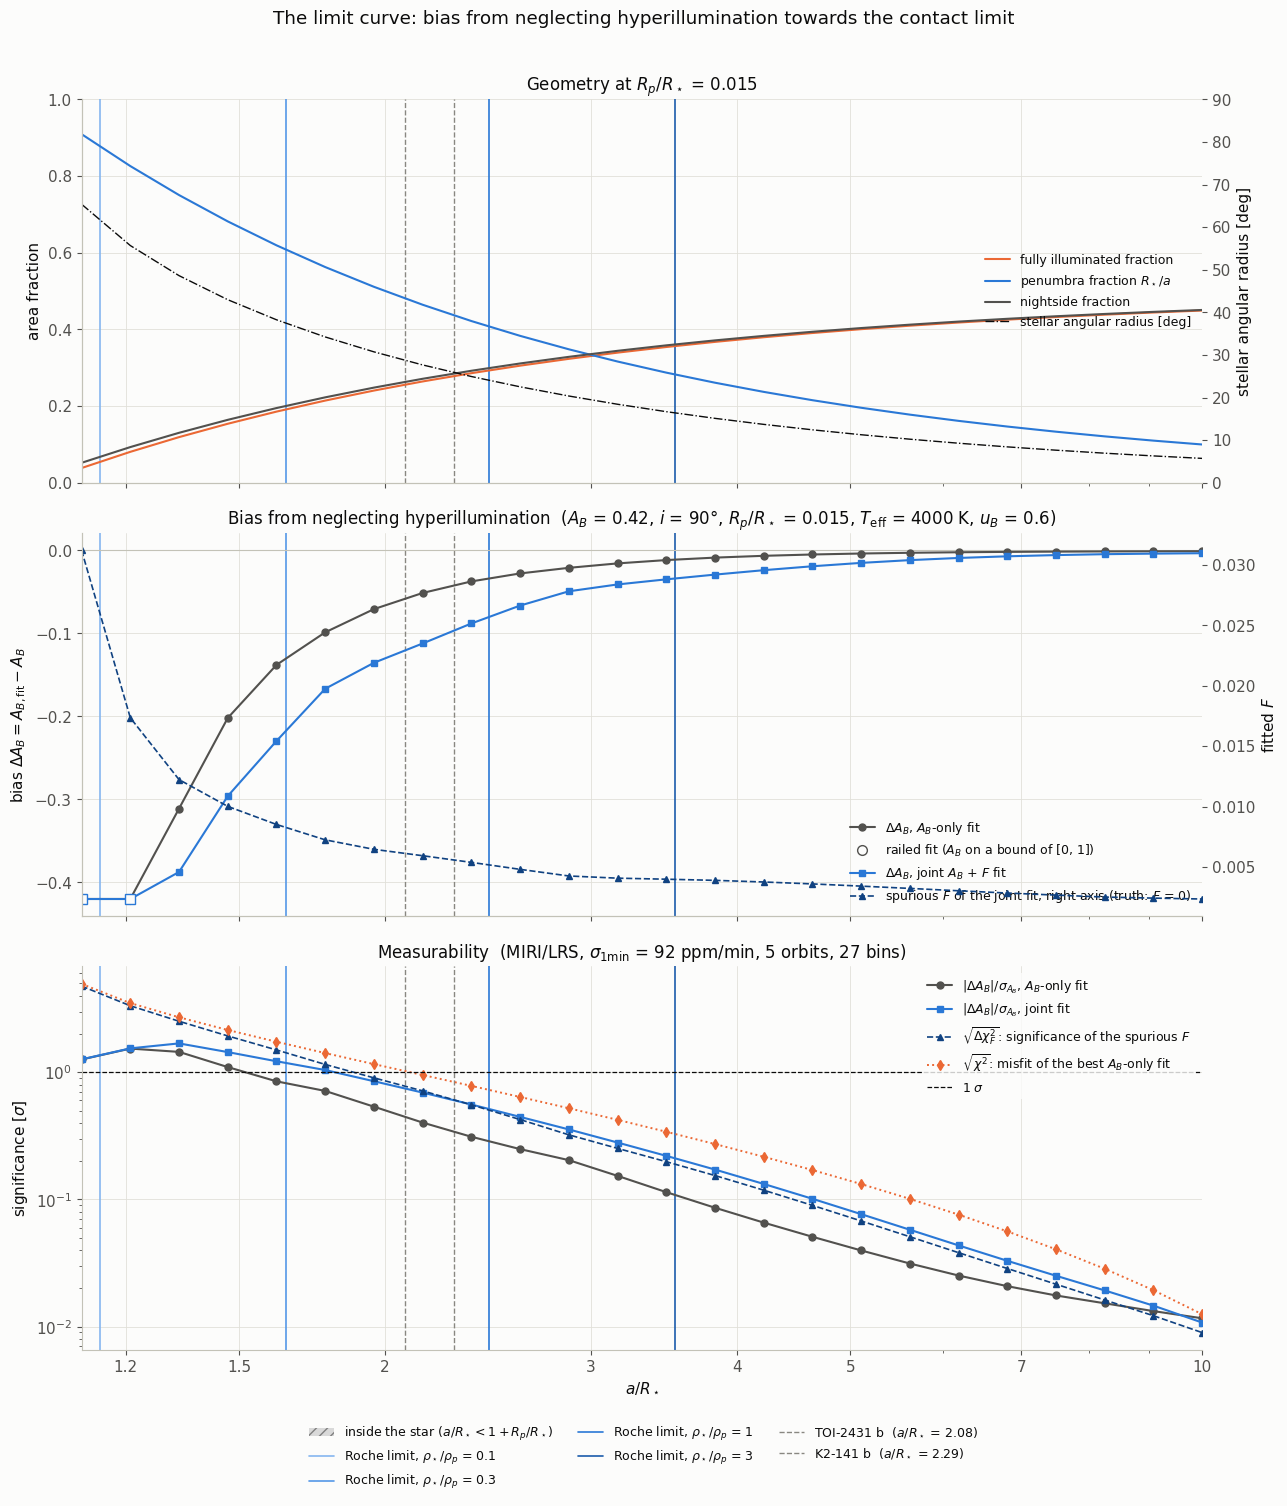

A_B-only fit railed at 2 of 24 points (a/Rs <= 1.211);  joint fit railed at 2 (a/Rs <= 1.211)
largest non-railed |Delta A_B|, A_B-only: -0.311 (-74.1 % of A_B) at a/Rs = 1.333
largest non-railed |Delta A_B|, joint:     -0.387 (-92.2 % of A_B) at a/Rs = 1.333;  largest spurious F = 0.0122
at the Roche limit of rho_star/rho_p = 0.1  (a/Rs = 1.14): Delta A_B = -0.420 (A_B-only), -0.420 (joint), F = 0.0262, misfit 4.48 sigma
at the Roche limit of rho_star/rho_p = 0.3  (a/Rs = 1.64): Delta A_B = -0.131 (A_B-only), -0.218 (joint), F = 0.0083, misfit 1.68 sigma
at the Roche limit of rho_star/rho_p = 1    (a/Rs = 2.46): Delta A_B = -0.034 (A_B-only), -0.080 (joint), F = 0.0052, misfit 0.73 sigma
at the Roche limit of rho_star/rho_p = 3    (a/Rs = 3.54): Delta A_B = -0.011 (A_B-only), -0.034 (joint), F = 0.0040, misfit 0.33 sigma


In [6]:
PAPER_MODE = False
a_rs_min, a_rs_max, n_sweep = 1.1, 10., 24   # a_rs_min: just outside the contact limit 1 + rp_rs_ref
a_rs_sweep = np.geomspace(a_rs_min, a_rs_max, n_sweep)
cfg_sweep = replace(cfg, sigma_1min=sigma_sweep)

sweep = bias_vs_a_rs(cfg_sweep, A_B_true, a_rs_sweep, rho_star=float(rho_star(T_eff_ref)), **kw)
geo = sweep_geometry(cfg, a_rs_sweep)
fig, axs = plot_limit_curve(sweep, geo, cfg_sweep, rp_rs_ref, RHO_RATIOS, anchors, u_B=u_B,
                            titles=(None, rf"Bias from neglecting hyperillumination  ({geom}, $R_p/R_\star$ = {rp_rs_ref:g}, $T_{{\rm eff}}$ = {T_eff_ref:g} K, $u_B$ = {u_B:g})",
                                    rf"Measurability  ({instrument}, $\sigma_{{1\rm min}}$ = {cfg_sweep.sigma_1min:.0f} ppm/min, {cfg_sweep.n_orbits} orbits, {cfg_sweep.n_bins} bins)"))
paper_figure("extreme_limit_curve", PAPER_MODE, fig=fig, tight=False)   # plot_limit_curve lays out its own legend room with tight_layout(rect=...)
plt.show()
print_limit_curve(sweep, A_B_true, RHO_RATIOS)

## 3. Figure B: the Roche frontier on the $(a/R_\star, T_{\rm eff})$ bias map

The map of `Bias_Maps.ipynb` §1.1 reaching down to `a_rs_grid_B[0]` and across F-to-M hosts, with the Roche limit $a_{\rm R}/R_\star(T_{\rm eff}) = c\,[\rho_\star(T_{\rm eff})/\rho_p]^{1/3}$ drawn through it for the compositions of `RHO_P_CASES` (`draw_roche_frontier`); left of the densest composition's curve no rocky planet can sit (hatched). `print_allowed_extremes` gives the largest bias inside each allowed region -- the physically reachable extreme instead of the box's corner. The kinks of the curves are the steps of the coarse main-sequence table.

What to look for: the frontier runs diagonally -- the strongly biased lower-left corner is forbidden around M dwarfs and open around F and G stars, so the reachable extreme sits at the hot, low-density end.

non-railed cells: 126 of 135;  Delta A_B in [-0.292, -0.006] = [-69.6, -1.4] % of A_B
railed: 9


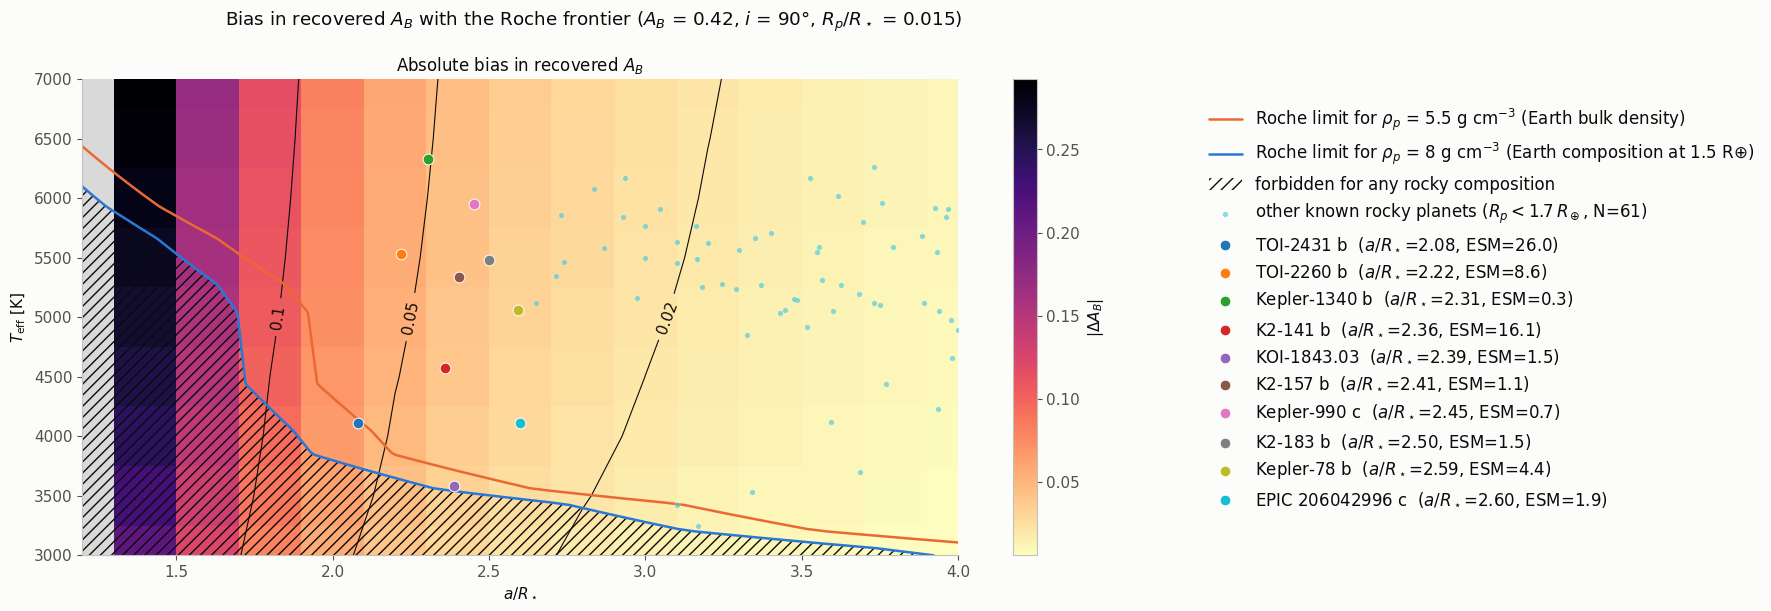

non-railed cells: 126 of 135;  largest |Delta A_B| on the whole box: 0.292
  beyond the Roche limit for rho_p = 5.5 g/cm^3 (Earth bulk density): 91 cells allowed, largest |Delta A_B| = 0.292 (69.6 % of A_B) at a/Rs = 1.40, T_eff = 7000 K
  beyond the Roche limit for rho_p = 8 g/cm^3 (Earth composition at 1.5 R⊕): 99 cells allowed, largest |Delta A_B| = 0.292 (69.6 % of A_B) at a/Rs = 1.40, T_eff = 7000 K


In [7]:
PAPER_MODE = False
a_rs_grid_B = map_grid(1.2, 4.0, 15)
T_eff_grid_B = map_grid(3000., 7000., 9)
bias_map_B = bias_map_grid(cfg, A_B_true, a_rs_grid_B, T_eff_grid_B, "T_s", **kw)   # A_B-only fit, cells in parallel, noise-independent
fig, axs = plot_bias_maps(a_rs_grid_B, T_eff_grid_B, bias_map_B, A_B_true, AGG, "st_teff", r"$T_{\rm eff}$ [K]", rp_rs_of=lambda y: np.full_like(y, rp_rs_ref), incl=incl_ref,
               overlay=lambda ax: draw_roche_frontier(ax, a_rs_grid_B, T_eff_grid_B, RHO_P_CASES, rp_rs_ref),
               title=rf"Bias in recovered $A_B$ with the Roche frontier ({geom}, $R_p/R_\star$ = {rp_rs_ref:g})")
paper_figure("extreme_biasmap_roche", PAPER_MODE, fig=fig)
plt.show()
print_allowed_extremes(a_rs_grid_B, T_eff_grid_B, bias_map_B, A_B_true, roche_allowed_masks(a_rs_grid_B, T_eff_grid_B, RHO_P_CASES), RHO_P_CASES)

## 4. Figure C: the Roche-limit planets

One planet per density ratio in `RHO_RATIOS` (`roche_planet`), of mean density `RHO_P_REF`, exactly at its Roche limit: $a/R_\star$ and the period follow from $(\rho_\star/\rho_p, \rho_p)$, $T_{\rm eff}$ and $R_\star$ from the main-sequence table, $R_p/R_\star$ and the inclination are the reference values. The number in a planet's name is its $\rho_\star/\rho_p$. The hypothetical planets share the noise `sigma_sweep`; the anchors have their own PandExo noise.

In [8]:
roche_planets = {pl.name: pl for pl in (roche_planet(r, RHO_P_REF, rp_rs=rp_rs_ref, incl=incl_ref) for r in RHO_RATIOS)}
for pl in roche_planets.values():
    print(f"{pl.name}: a/Rs = {pl.R / pl.r2:.3f}, P = {pl.period * 24:.2f} h, T_eff = {pl.T2_eff:.0f} K, {100 * pl.fraction_illuminated():.1f} % illuminated")

Roche-limit planet (0.1): a/Rs = 1.140, P = 4.49 h, T_eff = 6236 K, 93.2 % illuminated
Roche-limit planet (0.3): a/Rs = 1.644, P = 4.49 h, T_eff = 5225 K, 80.0 % illuminated
Roche-limit planet (1): a/Rs = 2.456, P = 4.49 h, T_eff = 3518 K, 70.1 % illuminated
Roche-limit planet (3): a/Rs = 3.542, P = 4.49 h, T_eff = 3105 K, 63.9 % illuminated


### 4.1 One case: light curve and residuals
`case_ratio` selects the planet (`plot_fit_vs_truth`): the truth with the best $A_B$-only and joint fits and one mock noise realisation, and the residuals before and after absorbing the bias. What to look for: whether the fits are distinguishable from the truth by eye at this noise, and which part of the orbit carries the irreducible residual.

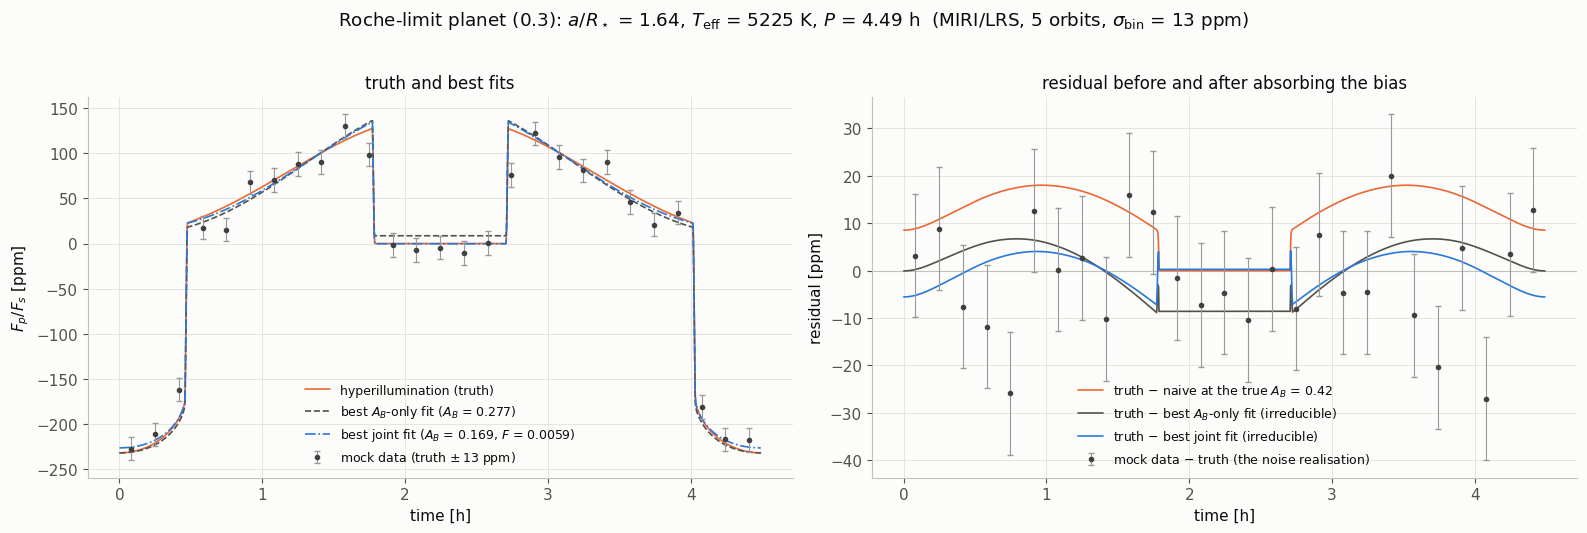

A_B-only: A_B 0.420 -> 0.277 (-34.0 %), Fisher sigma 0.144, misfit sqrt(chi2) = 2.26 sigma
joint:    A_B 0.420 -> 0.169 (-59.7 %), Fisher sigma 0.169, F = 0.0059, spurious F at sqrt(dchi2_F) = 1.96 sigma


In [9]:
PAPER_MODE = False
case_ratio = 0.3   # an entry of RHO_RATIOS
case_planet = roche_planet(case_ratio, RHO_P_REF, rp_rs=rp_rs_ref, incl=incl_ref)
cfg_case = replace(cfg, planet=case_planet, sigma_1min=sigma_sweep)
fit_case = fit_truth(cfg_case, A_B_true, models=("naive", "naive_redist"), free_offset=True, bounds=(0., 1.), fisher=True, **kw)
n_, j_ = fit_case["naive"], fit_case["naive_redist"]
fig, ax = plot_fit_vs_truth(cfg_case, A_B_true, fit_case, **kw,
                            title=rf"{case_planet.name}: $a/R_\star$ = {case_planet.R / case_planet.r2:.2f}, $T_{{\rm eff}}$ = {case_planet.T2_eff:.0f} K, $P$ = {24 * case_planet.period:.2f} h  ({instrument}, {cfg_case.n_orbits} orbits, $\sigma_{{\rm bin}}$ = {cfg_case.sigma_bin:.0f} ppm)")
paper_figure(f"extreme_fit_vs_truth_{case_planet.name.replace(' ', '')}", PAPER_MODE, fig=fig)
plt.show()
print(f"A_B-only: A_B {A_B_true:.3f} -> {n_['A_B_fit']:.3f} ({100 * n_['bias_A_B'] / A_B_true:+.1f} %), Fisher sigma {n_['sigma_A_B']:.3f}, misfit sqrt(chi2) = {np.sqrt(n_['chi2']):.2f} sigma")
print(f"joint:    A_B {A_B_true:.3f} -> {j_['A_B_fit']:.3f} ({100 * j_['bias_A_B'] / A_B_true:+.1f} %), Fisher sigma {j_['sigma_A_B']:.3f}, F = {j_['F_fit']:.4f}, spurious F at sqrt(dchi2_F) = {np.sqrt(max(n_['chi2'] - j_['chi2'], 0.)):.2f} sigma")

### 4.2 Temperature maps
Hyperillumination (top) and point-source (bottom) maps of every Roche-limit planet at quadrature (`plot_model_insolmaps`), one colour scale per planet, terminator in grey, penumbra borders in green. What to look for: how the penumbra swallows the nightside as the density ratio falls.

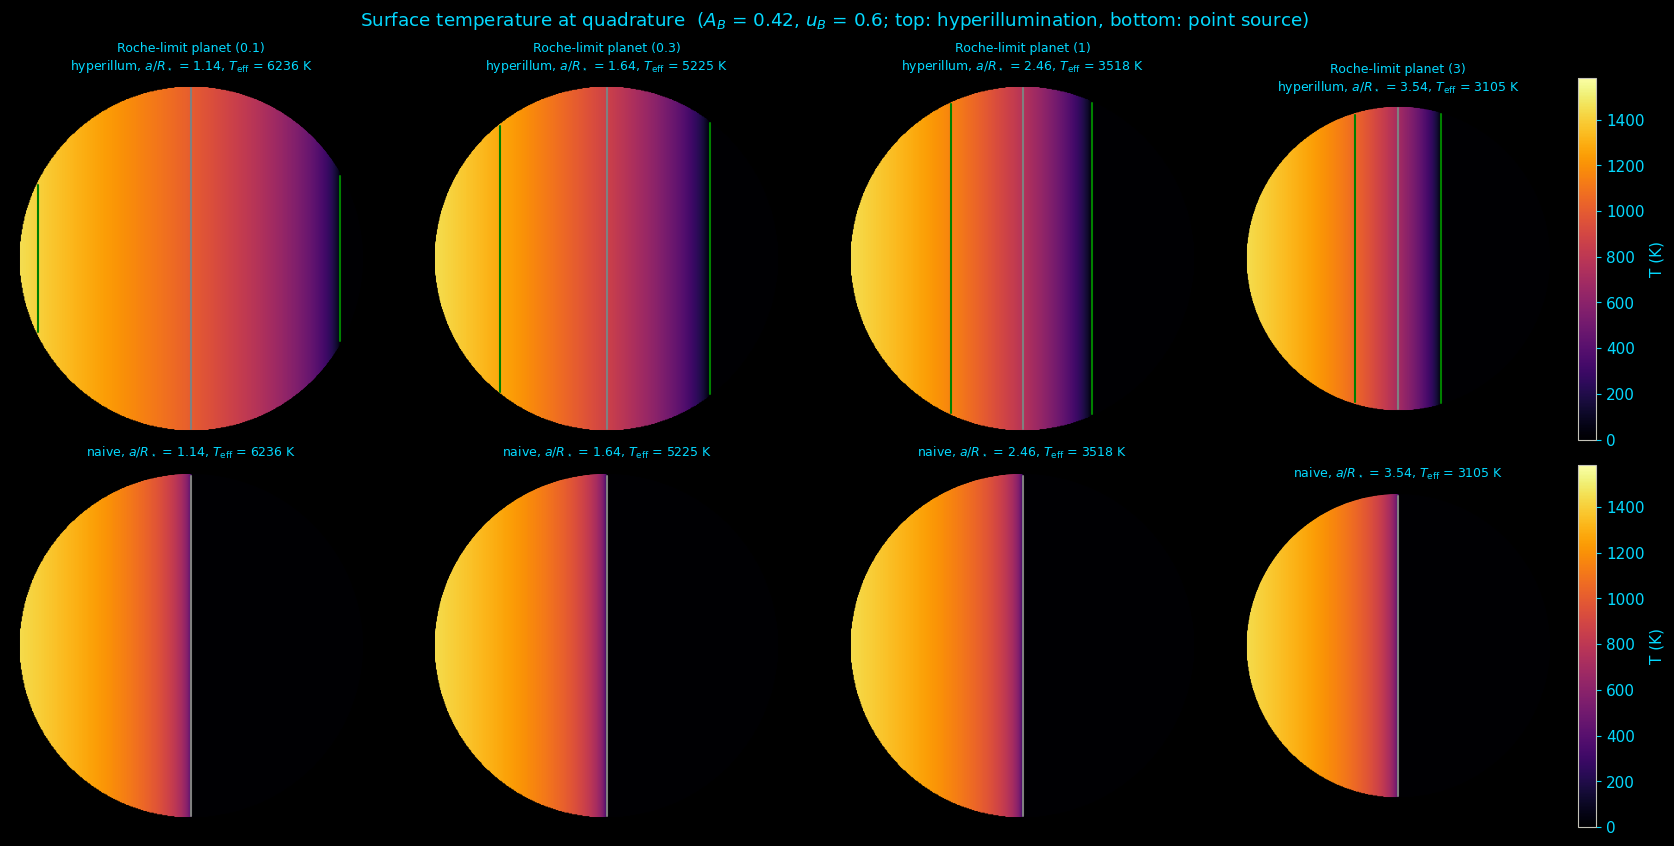

In [10]:
PAPER_MODE = False
fig, axs = plot_model_insolmaps(roche_planets, phase=0.25, u_B=u_B, A_B=A_B_true, theme=paper_theme(PAPER_MODE), title=rf"Surface temperature at quadrature  ($A_B$ = {A_B_true:.2f}, $u_B$ = {u_B:g}; top: hyperillumination, bottom: point source)")
paper_figure("extreme_tempmaps_roche", PAPER_MODE, fig=fig)
plt.show()

### 4.3 Retrieval next to the anchors
Every Roche-limit planet and anchor fitted at its own geometry. First the figure of `Bias_Maps.ipynb` §2.3 with planets on the x axis: the retrieved $A_B$ of the $A_B$-only fit (circles) and of the joint fit (squares) with Fisher $1\sigma$ / $2\sigma$ bars against the injected $A_B$ (dashed); a hollow marker is an unconstrained fit. Then the false-positive test of §2.5 per planet (`plot_false_F_bars`): one bar at $\sqrt{\Delta\chi^2_F}$, the expected significance with which the joint fit would report $F > 0$ on data without redistribution, against the `z_false` threshold, with the fitted $F$, the implied nightside temperature and the critical noise and observing time under the axis. (Fisher $\sigma_F$ is not used: the model goes as $F^{1/4}$ and the $F = 0$ boundary makes it meaningless, see `fisher_sigma`.)

What to look for: whether the injected $A_B$ lies inside each planet's bars and how far the joint squares sit below the circles; which planets cross the false-positive threshold, i.e. where a naive fit would report an atmosphere that is not there; which fits rail (listed below).

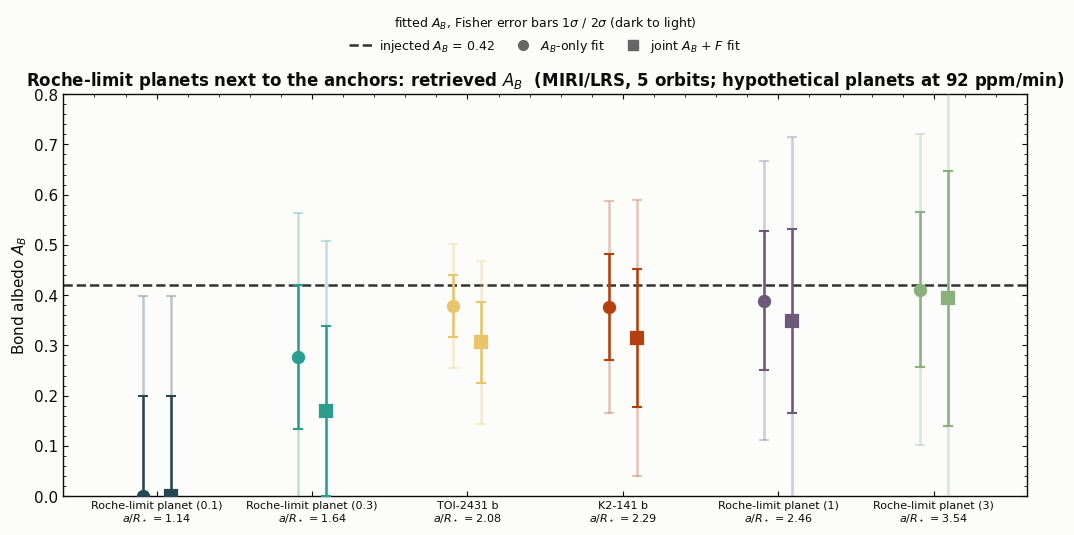

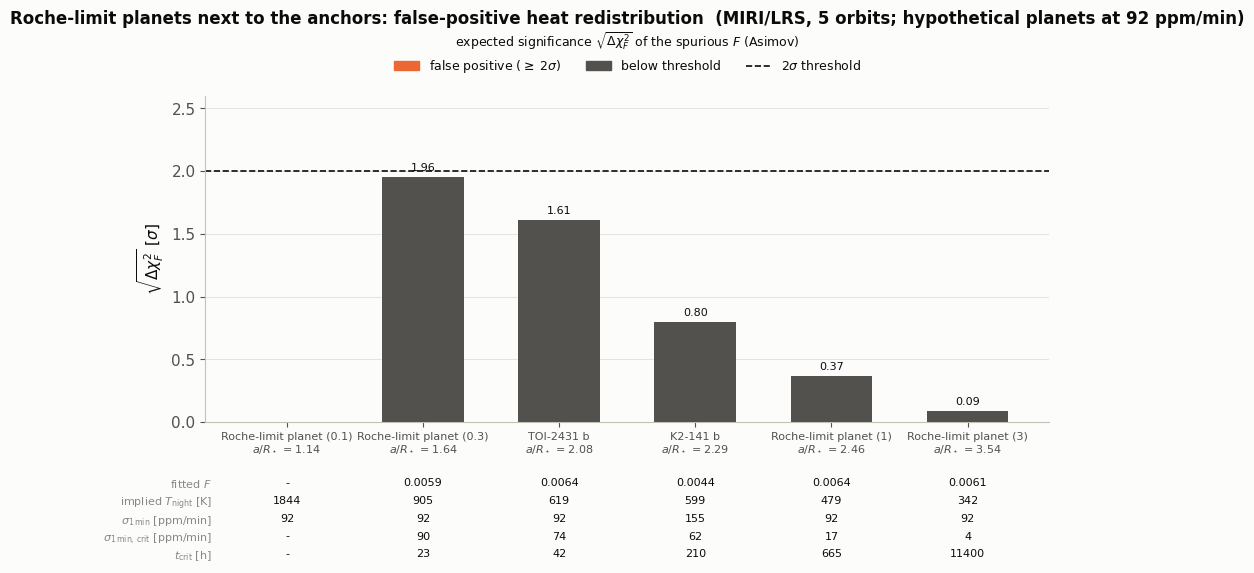

                    name  a_rs  T_eff   A_B_fit  sigma_A_B  bias_sigma          verdict  A_B_fit_J    F_fit     z_F
Roche-limit planet (0.1)  1.14   6236 3.431e-05     0.1996       2.104 needs hyperillum  3.511e-06  0.01988     NaN
Roche-limit planet (0.3) 1.644   5225    0.2771     0.1436      0.9954         naive OK     0.1691 0.005856   1.957
              TOI-2431 b 2.081   4109    0.3783    0.06152      0.6777         naive OK     0.3059 0.006409   1.609
                K2-141 b 2.292   4599    0.3759     0.1052      0.4191         naive OK     0.3146 0.004417  0.8014
  Roche-limit planet (1) 2.456   3518    0.3891     0.1386      0.2226         naive OK     0.3484 0.006353  0.3676
  Roche-limit planet (3) 3.542   3105    0.4111     0.1549     0.05731         naive OK     0.3935 0.006103 0.08877
railed: A_B-only Roche-limit planet (0.1);  joint Roche-limit planet (0.1)


In [11]:
PAPER_MODE = False
case_planets = {**roche_planets, **anchors}
sigma_case = {**{nm: sigma_sweep for nm in roche_planets}, **sigma_anchors}
title_tail = f"({instrument}, {cfg.n_orbits} orbits; hypothetical planets at {sigma_sweep:.0f} ppm/min)"

tab_case = planet_bias_table(cfg, A_B_true, case_planets, sigma_case, AGG=AGG, **kw)                  # A_B-only fit
tab_case_J = planet_bias_table(cfg, A_B_true, case_planets, sigma_case, redist=True, AGG=AGG, **kw)   # joint A_B + F fit
fig, ax = plot_instrument_retrievals({"$A_B$-only fit": tab_case, "joint $A_B$ + $F$ fit": tab_case_J}, xcol="name", title=f"Roche-limit planets next to the anchors: retrieved $A_B$  {title_tail}")
paper_figure("extreme_retrieval_roche", PAPER_MODE, fig=fig)
plt.show()

z_false = 2.   # the false positive's significance [sigma] the verdict refers to
tab_false = planet_false_F_table(cfg, A_B_true, case_planets, sigma_case, z=z_false, AGG=AGG, **kw)
fig, ax = plot_false_F_bars(tab_false, title=f"Roche-limit planets next to the anchors: false-positive heat redistribution  {title_tail}")
paper_figure("extreme_falseF_roche", PAPER_MODE, fig=fig, tight=False)   # plot_false_F_bars places the parameter rows with subplots_adjust
plt.show()

summary = tab_case[["name", "a_rs", "T_eff", "A_B_fit", "sigma_A_B", "bias_sigma", "verdict"]].merge(tab_case_J[["name", "A_B_fit", "F_fit"]].rename(columns={"A_B_fit": "A_B_fit_J"}), on="name").merge(tab_false[["name", "z_F"]], on="name")
print(summary.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
print("railed: A_B-only " + (", ".join(railed_names(tab_case, A_B_true)) or "none") + ";  joint " + (", ".join(railed_names(tab_case_J, A_B_true)) or "none"))